***Electricity Hourly Demand Forecasting***

In [3]:
# import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import warnings
warnings.filterwarnings("ignore")

In [4]:
# Load dataset

df = pd.read_csv("Electricity Demand Dataset.csv")

In [5]:
df

,Timestamp,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
0,01-Jan-20,0.0,2.0,1.0,2020.0,1.0,3.000000,61.288951,2457.119872
1,01-Jan-20,1.0,2.0,1.0,2020.0,1.0,3.000000,52.873702,2269.904712
2,01-Jan-20,2.0,2.0,1.0,2020.0,1.0,4.244482,36.341783,2215.640403
3,01-Jan-20,3.0,2.0,1.0,2020.0,1.0,3.000000,72.629378,2174.232413
4,01-Jan-20,4.0,2.0,1.0,2020.0,1.0,3.881208,90.582444,2472.453006
...,...,...,...,...,...,...,...,...,...
43843,31-Dec-24,19.0,1.0,12.0,2024.0,366.0,3.956838,43.287161,4689.693109
43844,31-Dec-24,20.0,1.0,12.0,2024.0,366.0,3.118824,51.705756,4331.249224
43845,31-Dec-24,21.0,1.0,12.0,2024.0,366.0,3.000000,40.565916,4015.979957
43846,31-Dec-24,22.0,1.0,12.0,2024.0,366.0,3.000000,51.998107,3353.241682


In [6]:
df.info

<bound method DataFrame.info of        Timestamp  hour  dayofweek  month    year  dayofyear  Temperature  \
0      01-Jan-20   0.0        2.0    1.0  2020.0        1.0     3.000000   
1      01-Jan-20   1.0        2.0    1.0  2020.0        1.0     3.000000   
2      01-Jan-20   2.0        2.0    1.0  2020.0        1.0     4.244482   
3      01-Jan-20   3.0        2.0    1.0  2020.0        1.0     3.000000   
4      01-Jan-20   4.0        2.0    1.0  2020.0        1.0     3.881208   
...          ...   ...        ...    ...     ...        ...          ...   
43843  31-Dec-24  19.0        1.0   12.0  2024.0      366.0     3.956838   
43844  31-Dec-24  20.0        1.0   12.0  2024.0      366.0     3.118824   
43845  31-Dec-24  21.0        1.0   12.0  2024.0      366.0     3.000000   
43846  31-Dec-24  22.0        1.0   12.0  2024.0      366.0     3.000000   
43847  31-Dec-24  23.0        1.0   12.0  2024.0      366.0     6.037472   

        Humidity       Demand  
0      61.288951  2457.

In [7]:
# Convert timestamp column to datetime format

df['Timestamp'] = pd.to_datetime(df['Timestamp'])

In [8]:
# set timestamp as index

df = df.set_index('Timestamp')

In [9]:
df

,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
Timestamp,,,,,,,,
2020-01-01,0.0,2.0,1.0,2020.0,1.0,3.000000,61.288951,2457.119872
2020-01-01,1.0,2.0,1.0,2020.0,1.0,3.000000,52.873702,2269.904712
2020-01-01,2.0,2.0,1.0,2020.0,1.0,4.244482,36.341783,2215.640403
2020-01-01,3.0,2.0,1.0,2020.0,1.0,3.000000,72.629378,2174.232413
2020-01-01,4.0,2.0,1.0,2020.0,1.0,3.881208,90.582444,2472.453006
...,...,...,...,...,...,...,...,...
2024-12-31,19.0,1.0,12.0,2024.0,366.0,3.956838,43.287161,4689.693109
2024-12-31,20.0,1.0,12.0,2024.0,366.0,3.118824,51.705756,4331.249224
2024-12-31,21.0,1.0,12.0,2024.0,366.0,3.000000,40.565916,4015.979957


**Dataset Overview**

In [11]:
print("Number of rows:", len(df))
print("Number of columns:", df.shape[1])

print("\nStart date:", df.index.min())
print("End date:", df.index.max())

print("\nData types:")
display(df.dtypes)

print("\nDataset information:")
df.info()

Number of rows: 43848
Number of columns: 8

Start date: 2020-01-01 00:00:00
End date: 2024-12-31 00:00:00

Data types:


hour           float64
dayofweek      float64
month          float64
year           float64
dayofyear      float64
Temperature    float64
Humidity       float64
Demand         float64
dtype: object


Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 43848 entries, 2020-01-01 to 2024-12-31
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   hour         43837 non-null  float64
 1   dayofweek    43839 non-null  float64
 2   month        43840 non-null  float64
 3   year         43843 non-null  float64
 4   dayofyear    43843 non-null  float64
 5   Temperature  43841 non-null  float64
 6   Humidity     43838 non-null  float64
 7   Demand       43841 non-null  float64
dtypes: float64(8)
memory usage: 3.0 MB


In [13]:
# Statistical summary

display(
    df[
        ["Temperature", "Humidity", "Demand"]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Temperature,43841.0,25.067788,12.821725,3.00000,15.210186,25.003212,34.740971,50.0000
Humidity,43838.0,59.903007,18.342604,20.00000,46.241224,59.986720,73.796820,95.0000
Demand,43841.0,5000.790976,1412.527409,1611.95402,4015.668472,5013.053367,6000.803082,11910.7051


**Data Quality Analysis**

In [14]:
df.isnull().sum()

hour           11
dayofweek       9
month           8
year            5
dayofyear       5
Temperature     7
Humidity       10
Demand          7
dtype: int64

In [15]:
# Records that contain any null values

df[df.isna().any(axis=1)]

,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
Timestamp,,,,,,,,
2020-04-30,NaN,3.0,4.0,2020.0,121.0,21.820261,41.353675,5393.127681
2020-07-21,NaN,1.0,7.0,2020.0,203.0,36.555833,62.779665,6248.349423
2021-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-02-27,NaN,5.0,2.0,2021.0,58.0,24.001003,53.303268,4523.253789
2021-12-13,23.0,0.0,12.0,2021.0,NaN,3.000000,75.457130,3225.225822
2021-12-14,NaN,1.0,12.0,2021.0,348.0,5.061319,47.215825,2887.848612


In [16]:
# # Records that contain all null values

df[df.isna().all(axis=1)]

,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
Timestamp,,,,,,,,
2021-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# Drop records with all null values

df = df.dropna(how = 'all')

In [18]:
df[df.isna().all(axis=1)]

,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
Timestamp,,,,,,,,


In [19]:
# Check missing values again

df.isnull().sum()

hour           7
dayofweek      5
month          4
year           1
dayofyear      1
Temperature    3
Humidity       6
Demand         3
dtype: int64

In [20]:
# Applying ffill method on hour, dayofweek, month, year, dayofyear columns

df[['hour', 'dayofweek', 'month', 'year', 'dayofyear']] = df[['hour', 'dayofweek', 'month', 'year', 'dayofyear']].ffill()

In [21]:
df.isnull().sum()

hour           0
dayofweek      0
month          0
year           0
dayofyear      0
Temperature    3
Humidity       6
Demand         3
dtype: int64

In [22]:
# Applying bfill method on temprature and humidity

df[['Temperature', 'Humidity']] = df[['Temperature', 'Humidity']].bfill()

In [23]:
# Applying interpolate method on demand column

df['Demand'] = df['Demand'].interpolate(method = 'time')

In [24]:
df.isnull().sum()

hour           0
dayofweek      0
month          0
year           0
dayofyear      0
Temperature    0
Humidity       0
Demand         0
dtype: int64

In [54]:
# Create season column at third index in the dataset

df.insert(3, 'season', df.index.quarter)
df

,hour,dayofweek,month,season,year,dayofyear,Temperature,Humidity,Demand
Timestamp,,,,,,,,,
2020-01-01,0.0,2.0,1.0,1,2020.0,1.0,3.000000,61.288951,2457.119872
2020-01-01,1.0,2.0,1.0,1,2020.0,1.0,3.000000,52.873702,2269.904712
2020-01-01,2.0,2.0,1.0,1,2020.0,1.0,4.244482,36.341783,2215.640403
2020-01-01,3.0,2.0,1.0,1,2020.0,1.0,3.000000,72.629378,2174.232413
2020-01-01,4.0,2.0,1.0,1,2020.0,1.0,3.881208,90.582444,2472.453006
...,...,...,...,...,...,...,...,...,...
2024-12-31,19.0,1.0,12.0,4,2024.0,366.0,3.956838,43.287161,4689.693109
2024-12-31,20.0,1.0,12.0,4,2024.0,366.0,3.118824,51.705756,4331.249224
2024-12-31,21.0,1.0,12.0,4,2024.0,366.0,3.000000,40.565916,4015.979957


In [57]:
# Convert the datatype from float to integer

df[['hour', 'dayofweek', 'month','year', 'dayofyear']] = df[['hour', 'dayofweek', 'month','year', 'dayofyear']].astype(int)

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 43844 entries, 2020-01-01 to 2024-12-31
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   hour         43844 non-null  int64  
 1   dayofweek    43844 non-null  int64  
 2   month        43844 non-null  int64  
 3   season       43844 non-null  int32  
 4   year         43844 non-null  int64  
 5   dayofyear    43844 non-null  int64  
 6   Temperature  43844 non-null  float64
 7   Humidity     43844 non-null  float64
 8   Demand       43844 non-null  float64
dtypes: float64(3), int32(1), int64(5)
memory usage: 4.2 MB


In [65]:
# Create the WeekofYear column at 

df.insert(5, 'weekofyear', df.index.isocalendar().week.astype(int))
df

,hour,dayofweek,month,season,year,weekofyear,dayofyear,Temperature,Humidity,Demand
Timestamp,,,,,,,,,,
2020-01-01,0,2,1,1,2020,1,1,3.000000,61.288951,2457.119872
2020-01-01,1,2,1,1,2020,1,1,3.000000,52.873702,2269.904712
2020-01-01,2,2,1,1,2020,1,1,4.244482,36.341783,2215.640403
2020-01-01,3,2,1,1,2020,1,1,3.000000,72.629378,2174.232413
2020-01-01,4,2,1,1,2020,1,1,3.881208,90.582444,2472.453006
...,...,...,...,...,...,...,...,...,...,...
2024-12-31,19,1,12,4,2024,1,366,3.956838,43.287161,4689.693109
2024-12-31,20,1,12,4,2024,1,366,3.118824,51.705756,4331.249224
2024-12-31,21,1,12,4,2024,1,366,3.000000,40.565916,4015.979957


In [71]:
# Create a new column to check the Weekend

df.insert(7, 'is_weekend', df.index.dayofweek.isin([5,6]))
df['is_weekend'] = df['is_weekend'].astype(int)
df

,hour,dayofweek,month,season,year,weekofyear,dayofyear,is_weekend,Temperature,Humidity,Demand
Timestamp,,,,,,,,,,,
2020-01-01,0,2,1,1,2020,1,1,0,3.000000,61.288951,2457.119872
2020-01-01,1,2,1,1,2020,1,1,0,3.000000,52.873702,2269.904712
2020-01-01,2,2,1,1,2020,1,1,0,4.244482,36.341783,2215.640403
2020-01-01,3,2,1,1,2020,1,1,0,3.000000,72.629378,2174.232413
2020-01-01,4,2,1,1,2020,1,1,0,3.881208,90.582444,2472.453006
...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31,19,1,12,4,2024,1,366,0,3.956838,43.287161,4689.693109
2024-12-31,20,1,12,4,2024,1,366,0,3.118824,51.705756,4331.249224
2024-12-31,21,1,12,4,2024,1,366,0,3.000000,40.565916,4015.979957


In [79]:
import holidays

# create a new column that will show holidays, otherwise NaN

df['Holidays'] = holidays.IN(years = df.year)
df

,hour,dayofweek,month,season,year,weekofyear,dayofyear,is_weekend,Temperature,Humidity,Demand,Holidays
Timestamp,,,,,,,,,,,,
2020-01-01,0,2,1,1,2020,1,1,0,3.000000,61.288951,2457.119872,NaN
2020-01-01,1,2,1,1,2020,1,1,0,3.000000,52.873702,2269.904712,NaN
2020-01-01,2,2,1,1,2020,1,1,0,4.244482,36.341783,2215.640403,NaN
2020-01-01,3,2,1,1,2020,1,1,0,3.000000,72.629378,2174.232413,NaN
2020-01-01,4,2,1,1,2020,1,1,0,3.881208,90.582444,2472.453006,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31,19,1,12,4,2024,1,366,0,3.956838,43.287161,4689.693109,NaN
2024-12-31,20,1,12,4,2024,1,366,0,3.118824,51.705756,4331.249224,NaN
2024-12-31,21,1,12,4,2024,1,366,0,3.000000,40.565916,4015.979957,NaN


In [80]:
df.Holidays.value_counts()

Holidays
Republic Day                                     120
Holi                                             120
Christmas                                        120
Guru Nanak's Jayanti                             120
Diwali (Deepavali)                               120
Milad-un-Nabi                                    120
Dussehra                                         120
Mahatma Gandhi's Jayanti                         120
Muharram                                         120
Independence Day                                 120
Janmashtami (Vaishnava)                          120
Id-ul-Zuha (Bakrid)                              120
Id-ul-Fitr                                       120
Buddha Purnima                                   120
Good Friday                                      120
Dr. B. R. Ambedkar's Jayanti                      96
Mahavir Jayanti                                   96
Ram Navami                                        96
Maha Shivaratri                      

In [81]:
df = df.drop('Holidays', axis=1)

In [82]:
# Create a new column that will contain Demand from the same hour yesterday

df['Demand_lag_24hr'] = df['Demand'].shift(24)

In [84]:
# Create a new column that will contain Rolling Mean of the Demand in last 24 hours

df['demand_rolling_mean_24hr'] = df['Demand'].rolling(window=24).mean()

In [85]:
# Create a new column that will contain Rolling Standard Deviation of the Demand in last 24 hours

df['demand_rolling_std_24hr'] = df['Demand'].rolling(window=24).std()

In [90]:
# Drop all Rows having null values

df = df.dropna()
df

,hour,dayofweek,month,season,year,weekofyear,dayofyear,is_weekend,Temperature,Humidity,Demand,Demand_lag_24hr,demand_rolling_mean_24hr,demand_rolling_std_24hr
Timestamp,,,,,,,,,,,,,,
2020-01-02,0,3,1,1,2020,1,2,0,3.000000,54.022774,2322.713512,2457.119872,3819.369605,979.619652
2020-01-02,1,3,1,1,2020,1,2,0,3.140919,59.974324,2240.262042,2269.904712,3818.134493,981.674698
2020-01-02,2,3,1,1,2020,1,2,0,3.000000,62.307743,2181.594193,2215.640403,3816.715901,984.112675
2020-01-02,3,3,1,1,2020,1,2,0,5.206455,63.326154,2381.989864,2174.232413,3825.372462,969.847069
2020-01-02,4,3,1,1,2020,1,2,0,3.454380,55.066096,2400.170086,2472.453006,3822.360673,974.332989
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31,19,1,12,4,2024,1,366,0,3.956838,43.287161,4689.693109,5102.077310,4039.969992,976.961312
2024-12-31,20,1,12,4,2024,1,366,0,3.118824,51.705756,4331.249224,4187.844204,4045.945201,978.342615
2024-12-31,21,1,12,4,2024,1,366,0,3.000000,40.565916,4015.979957,3859.260701,4052.475170,977.565114


*Electricity Demand Over the Entire Period*

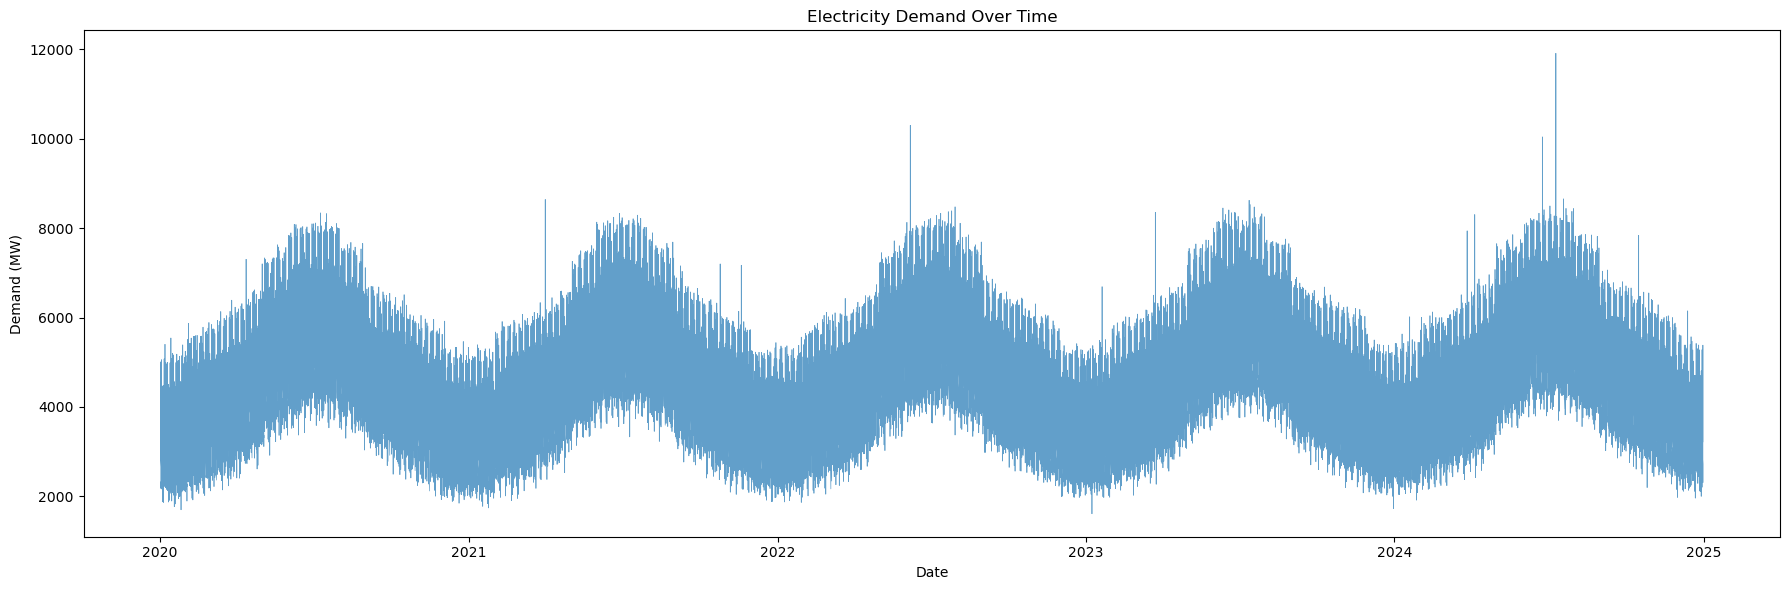

In [93]:
plt.figure(figsize=(18, 6))

plt.plot(
    df.index,
    df["Demand"],
    linewidth=0.5,
    alpha=0.7
)

plt.title("Electricity Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")

plt.tight_layout()
plt.show()

*Demand Distribution by Hour*

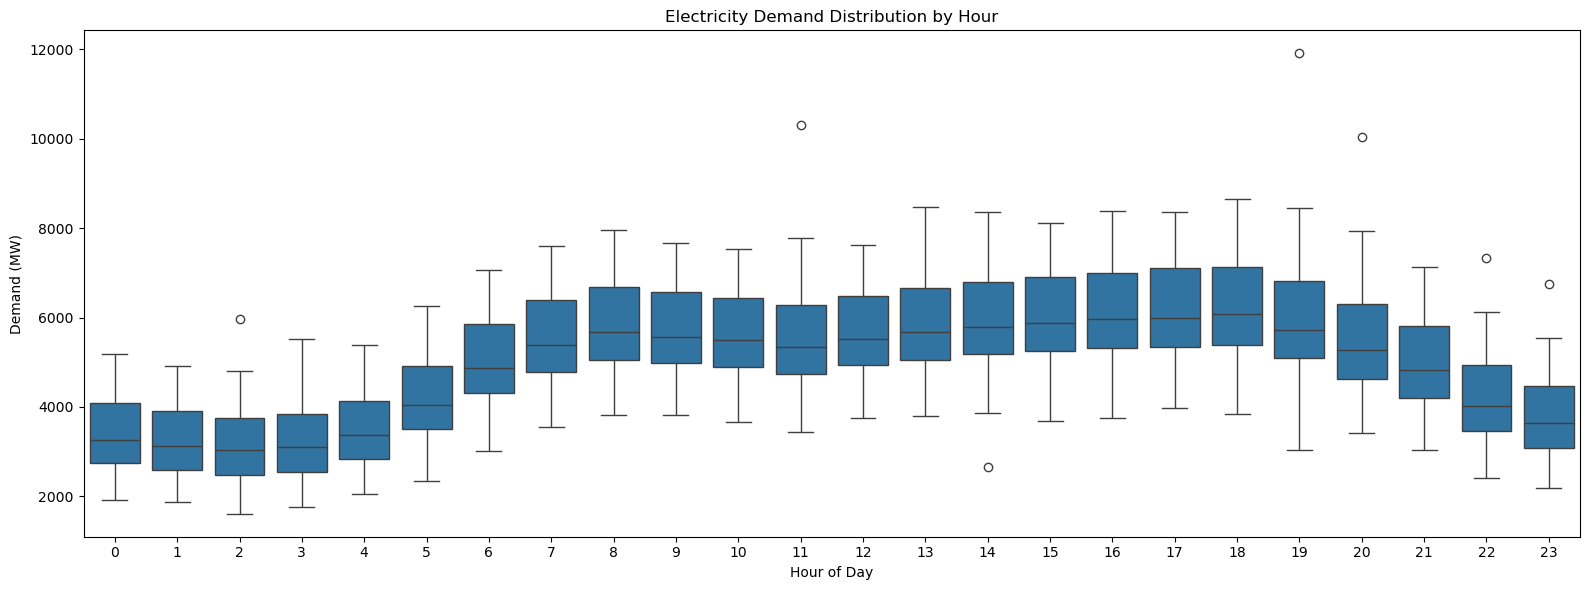

In [99]:
plt.figure(figsize=(16, 6))

sns.boxplot(
    data=df,
    x="hour",
    y="Demand"
)

plt.title("Electricity Demand Distribution by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Demand (MW)")

plt.tight_layout()
plt.show()

*Demand by Month*

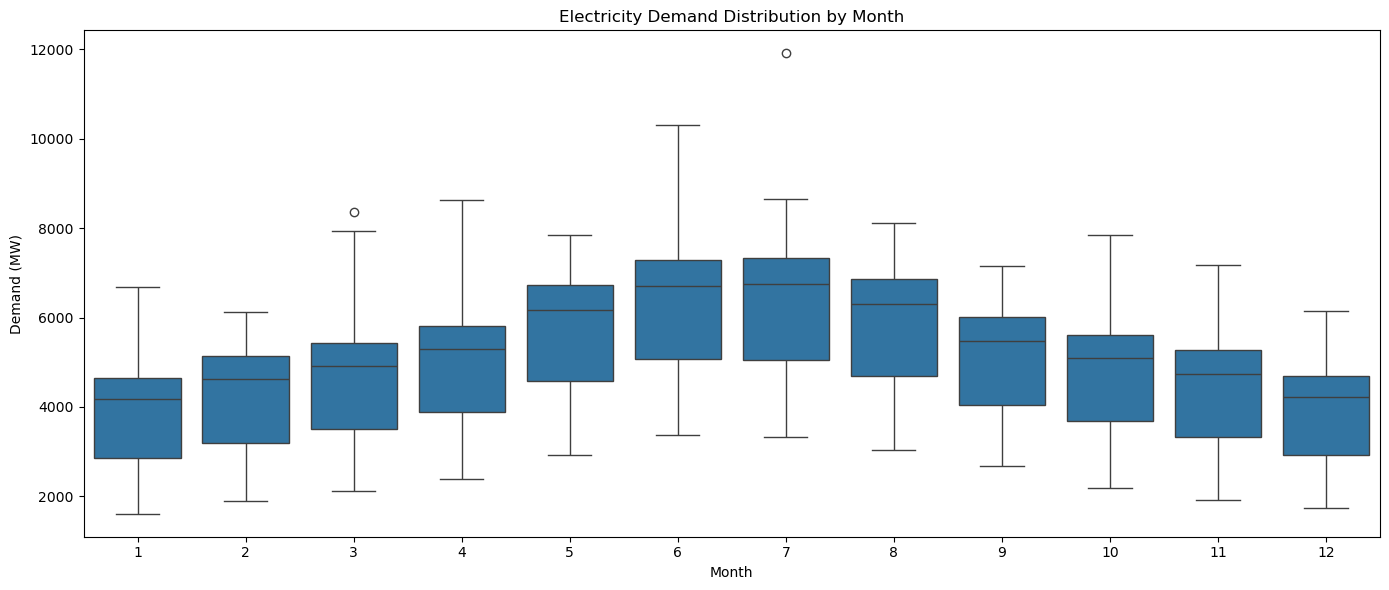

In [103]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="month",
    y="Demand"
)

plt.title("Electricity Demand Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Demand (MW)")

plt.tight_layout()
plt.show()

*Weekday vs Weekend*

In [106]:
weekend_demand = df.groupby("is_weekend")["Demand"].agg(
    ["mean", "median", "std"]
)

display(weekend_demand)

,mean,median,std
is_weekend,,,
0,5144.740119,5168.008243,1429.669776
1,4642.925699,4637.394335,1301.357501


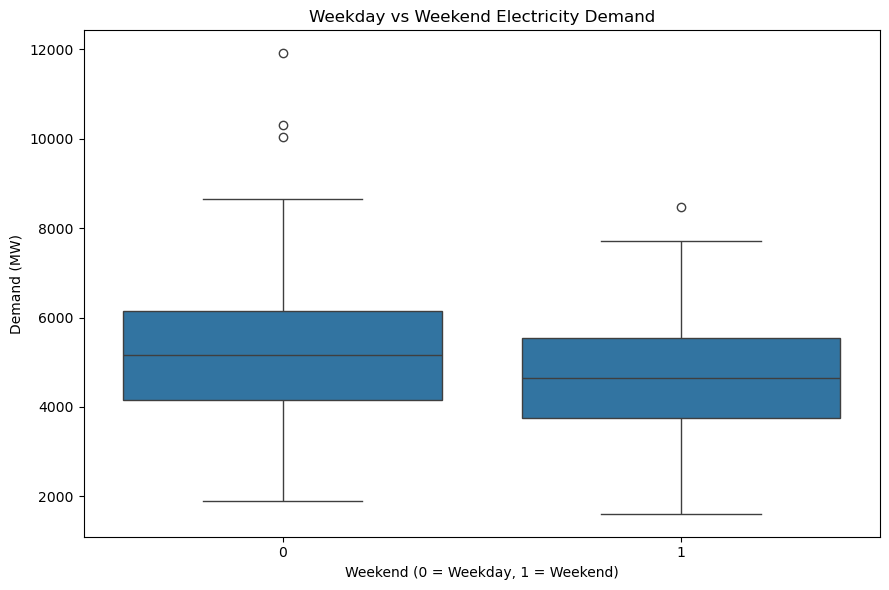

In [113]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="is_weekend",
    y="Demand"
)

plt.title("Weekday vs Weekend Electricity Demand")
plt.xlabel("Weekend (0 = Weekday, 1 = Weekend)")
plt.ylabel("Demand (MW)")

plt.tight_layout()
plt.show()

*Demand vs Temperature*

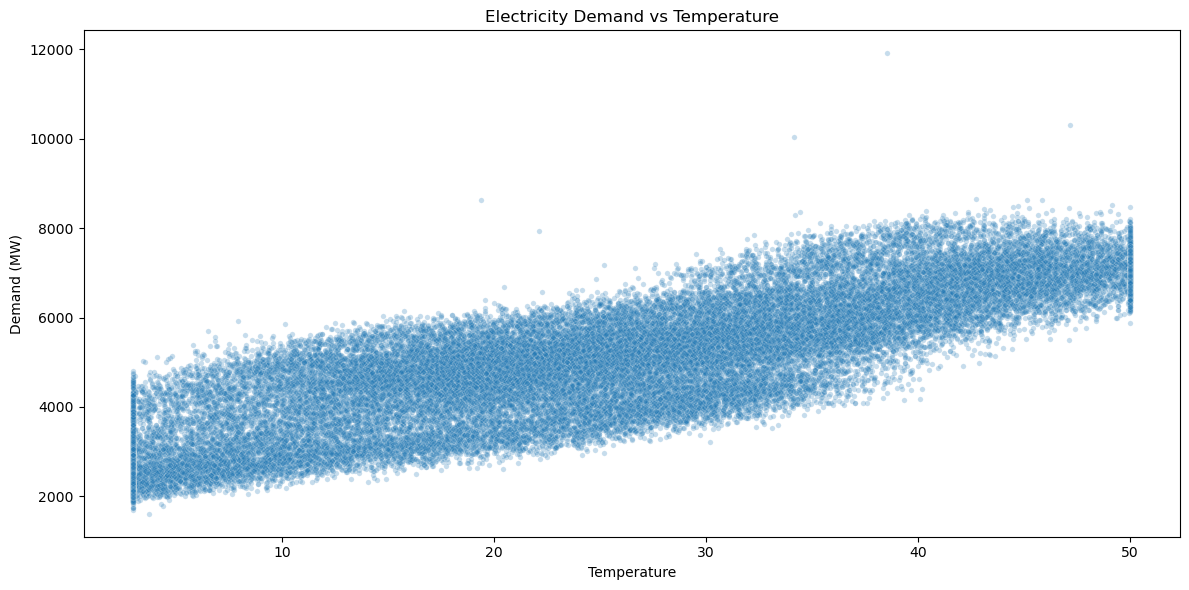

In [112]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="Temperature",
    y="Demand",
    alpha=0.25,
    s=15
)

plt.title("Electricity Demand vs Temperature")
plt.xlabel("Temperature")
plt.ylabel("Demand (MW)")

plt.tight_layout()
plt.show()

*Demand vs Humidity*

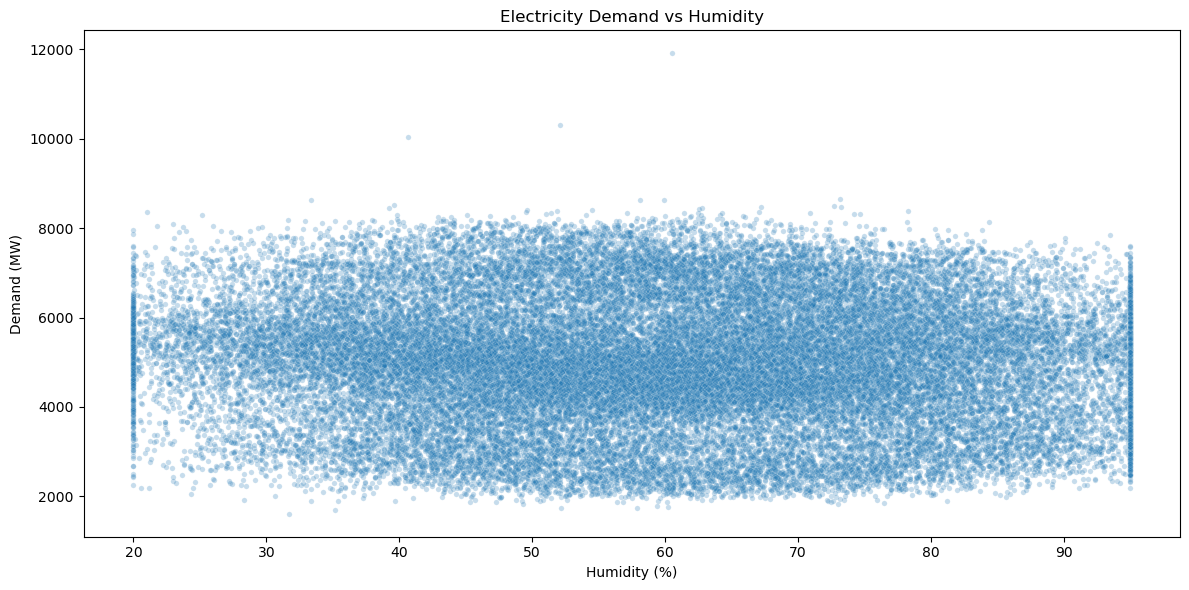

In [115]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="Humidity",
    y="Demand",
    alpha=0.25,
    s=15
)

plt.title("Electricity Demand vs Humidity")
plt.xlabel("Humidity (%)")
plt.ylabel("Demand (MW)")

plt.tight_layout()
plt.show()

**Correlation Analysis**

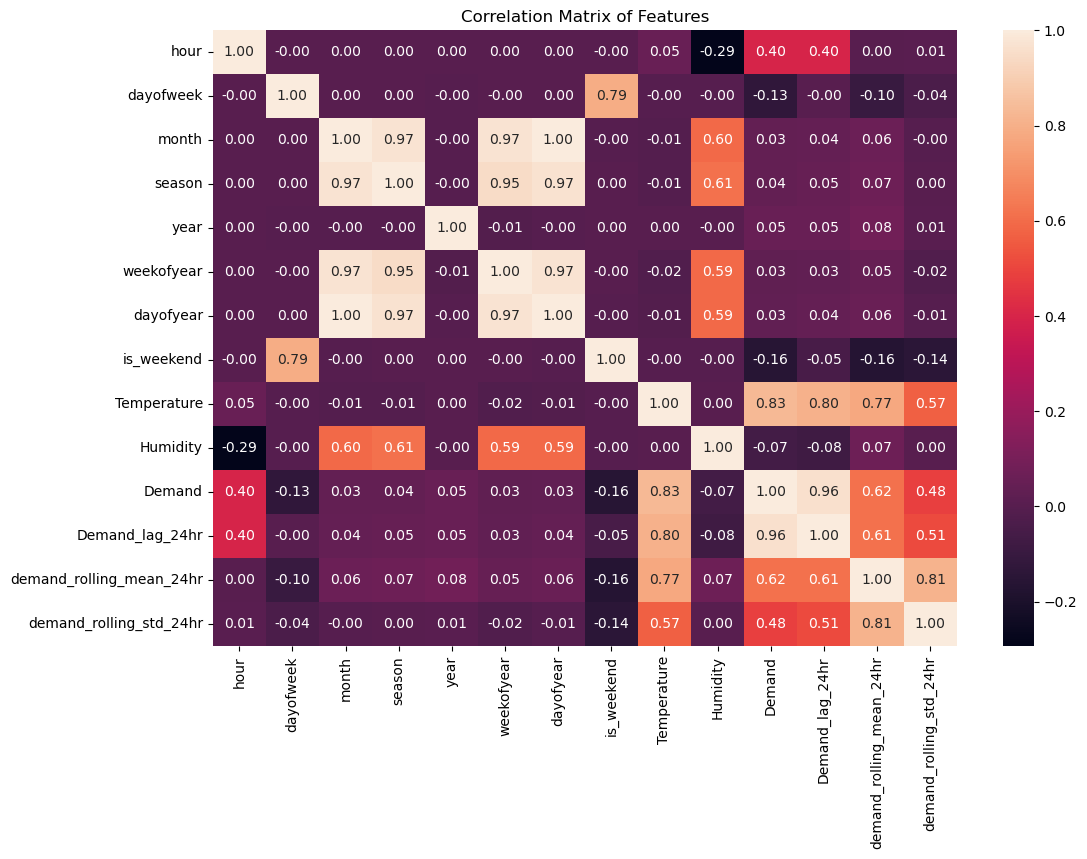

In [120]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot = True, fmt=".2f")
plt.title("Correlation Matrix of Features")
plt.show()

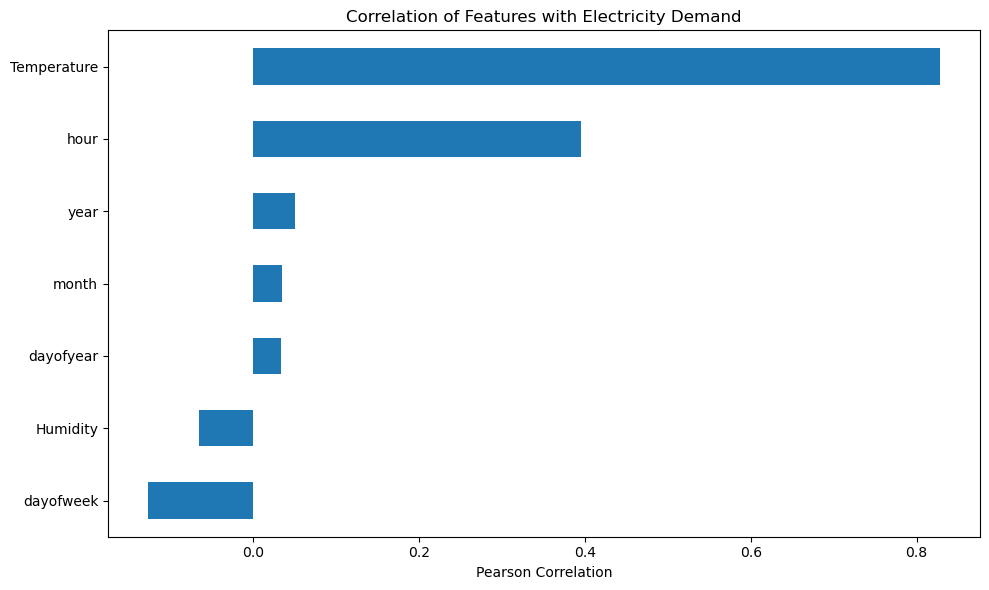

In [121]:
# Correlation of Demand with Other Features

demand_corr = (
    pearson_corr["Demand"]
    .drop("Demand")
    .sort_values()
)

plt.figure(figsize=(10, 6))

demand_corr.plot(kind="barh")

plt.title("Correlation of Features with Electricity Demand")
plt.xlabel("Pearson Correlation")

plt.tight_layout()
plt.show()

***train/test split***

In [122]:
Y = df.Demand
X = df.drop('Demand', axis=1) 

In [123]:
print(Y) 

Timestamp
2020-01-02    2322.713512
2020-01-02    2240.262042
2020-01-02    2181.594193
2020-01-02    2381.989864
2020-01-02    2400.170086
                 ...     
2024-12-31    4689.693109
2024-12-31    4331.249224
2024-12-31    4015.979957
2024-12-31    3353.241682
2024-12-31    3219.023339
Name: Demand, Length: 43820, dtype: float64


In [129]:
# Splitting the data into Training and Testing data

val_size = int(len(X_train) * 0.2)

In [130]:
X_train_sub = X_train.iloc[:-val_size]
Y_train_sub = Y_train.iloc[:-val_size]

In [131]:
# taking 20% of data as testing data

X_val = X_train.iloc[-val_size:]
Y_val = Y_train.iloc[-val_size:]  

In [132]:
print("Training:", X_train_sub.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)  

Training: (28029, 13)
Validation: (7007, 13)
Testing: (8784, 13)


***Linear Regression***

In [137]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Initialize the model
model_lr = LinearRegression()

# Train the model
model_lr.fit(X_train_sub, Y_train_sub)

# Make predictions
predictions_lr = model_lr.predict(X_val)

# Evaluate the model
rmse_lr = np.sqrt(mean_squared_error(Y_val, predictions_lr))
mae_lr = mean_absolute_error(Y_val, predictions_lr)

print('Linear Regression RMSE:', rmse_lr)
print('Linear Regression MAE:', mae_lr)

Linear Regression RMSE: 279.953650544163
Linear Regression MAE: 220.51504333207055


***Decision Tree Regressor***

In [138]:
from sklearn.tree import DecisionTreeRegressor

# Initialize the model
model_dt = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Train the model
model_dt.fit(X_train_sub, Y_train_sub)

# Make predictions
predictions_dt = model_dt.predict(X_test)

# Evaluate the model
rmse_dt = np.sqrt(mean_squared_error(Y_test, predictions_dt))
mae_dt = mean_absolute_error(Y_test, predictions_dt)

print('Decision Tree RMSE:', rmse_dt)
print('Decision Tree MAE:', mae_dt)

Decision Tree RMSE: 261.297815445519
Decision Tree MAE: 195.05108772141713


***Random Forest Regressor***

In [139]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the model
model_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=3,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

# Train the model
model_rf.fit(X_train_sub, Y_train_sub)

# Make predictions
predictions_rf = model_rf.predict(X_test)

# Evaluate the model
rmse_rf = np.sqrt(mean_squared_error(Y_test, predictions_rf))
mae_rf = mean_absolute_error(Y_test, predictions_rf)

print('Random Forest RMSE:', rmse_rf)
print('Random Forest MAE:', mae_rf)

Random Forest RMSE: 205.68552364631068
Random Forest MAE: 147.76229247491352


***XGBoost***

In [142]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Initialize the model
model_xgb = XGBRegressor(
    n_estimators=1000,
    early_stopping_rounds=50,
    learning_rate=0.01,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror',
    eval_metric='rmse',
    n_jobs=-1
)

# Train the model
model_xgb.fit(
    X_train_sub,
    Y_train_sub,
    eval_set=[(X_val, Y_val)],
    verbose=False
)

# Make predictions on validation data
predictions_xgb = model_xgb.predict(X_val)

# Evaluate the model
rmse_xgb = np.sqrt(mean_squared_error(Y_val, predictions_xgb))
mae_xgb = mean_absolute_error(Y_val, predictions_xgb)

print('XGBoost RMSE:', rmse_xgb)
print('XGBoost MAE:', mae_xgb)

print('Best iteration:', model_xgb.best_iteration)

XGBoost RMSE: 146.3853331185249
XGBoost MAE: 112.7979290659073
Best iteration: 999


In [ ]:
models = {
    'Linear Regression': model_lr,
    'Decision Tree': model_dt,
    'Random Forest': model_rf
}

results = []

for name, model in models.items():

    predictions = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(Y_val, predictions))
    mae = mean_absolute_error(Y_val, predictions)
    r2 = r2_score(Y_val, predictions)

    results.append({
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2
    })

# Add XGBoost
predictions = model_xgb.predict(X_val)

results.append({
    'Model': 'XGBoost',
    'RMSE': np.sqrt(mean_squared_error(Y_val, predictions)),
    'MAE': mean_absolute_error(Y_val, predictions),
    'R2': r2_score(Y_val, predictions)
})

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

results_df

,Model,RMSE,MAE,R2
0,XG Boosting,146.385333,112.797929,0.989093
1,XGBoost,146.385333,112.797929,0.989093
2,Random Forest,177.415869,135.905345,0.983979
3,Decision Tree,242.593321,188.520631,0.970046
4,Linear Regression,279.953651,220.515043,0.960110


In [167]:
import joblib

# Load saved models

loaded_model_lr = joblib.load('electricity_demand_lr_prediction_model.pkl')
loaded_model_dt = joblib.load('electricity_demand_dt_prediction_model.pkl')
loaded_model_rf = joblib.load('electricity_demand_rf_prediction_model.pkl')
loaded_model_xgb = joblib.load('electricity_demand_xgb_prediction_model.pkl')

print("All models loaded successfully!")

All models loaded successfully!


In [168]:
models_predictions = {
    'Linear Regression': loaded_model_lr.predict(X_test),
    'Decision Tree': loaded_model_dt.predict(X_test),
    'Random Forest': loaded_model_rf.predict(X_test),
    'XGBoost': loaded_model_xgb.predict(X_test)
}

***Models comparison**

In [169]:
comparison_df = pd.DataFrame({
    'Actual_Demand': Y_test,
    'Linear_Regression': predictions_lr,
    'Decision_Tree': predictions_dt,
    'Random_Forest': predictions_rf,
    'XGBoost': predictions_xgb
})

comparison_df.head(24)

,Actual_Demand,Linear_Regression,Decision_Tree,Random_Forest,XGBoost
Timestamp,,,,,
2024-01-01,2720.606072,2643.276391,2522.867083,2594.873625,2603.462891
2024-01-01,2669.647167,2644.815065,2425.913553,2509.845179,2488.298584
2024-01-01,2435.578924,2270.053656,2263.598443,2378.567840,2365.463379
2024-01-01,2641.043699,2812.993277,2600.061259,2531.307443,2576.003418
2024-01-01,2687.949643,2969.947801,2470.115688,2528.712149,2597.594727
2024-01-01,3309.357599,3516.186680,3470.184595,3662.669599,3388.931641
2024-01-01,4084.103103,3739.635775,3941.210209,3812.762617,3811.966553
2024-01-01,4599.967024,4521.565837,4541.094891,4680.142037,4620.717773
2024-01-01,4889.096038,4500.551859,4586.381526,4640.388670,4721.078613


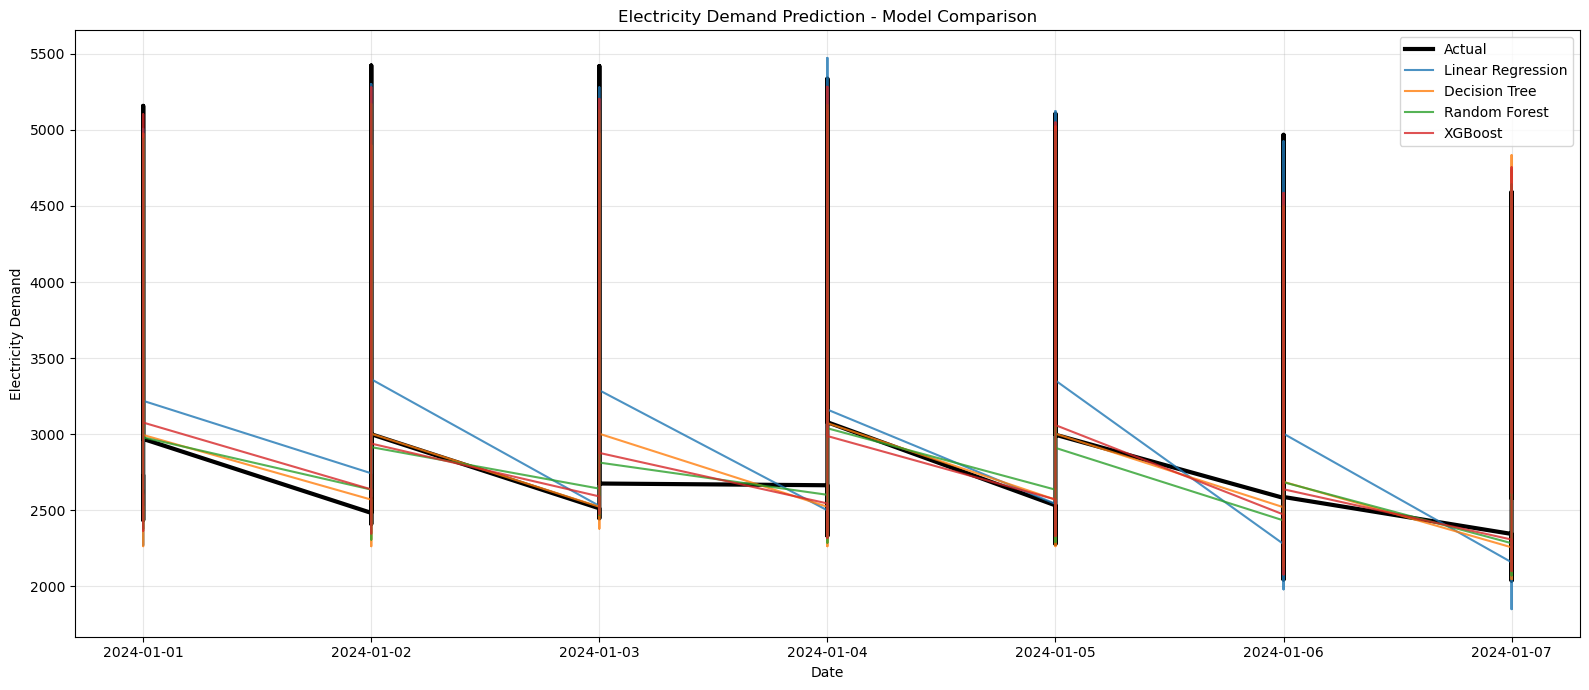

In [170]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

plt.plot(
    Y_test.index[:168],
    Y_test.iloc[:168],
    label='Actual',
    linewidth=3,
    color='black'
)

for name, predictions in models_predictions.items():
    plt.plot(
        Y_test.index[:168],
        predictions[:168],
        label=name,
        alpha=0.8
    )

plt.title('Electricity Demand Prediction - Model Comparison')
plt.xlabel('Date')
plt.ylabel('Electricity Demand')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

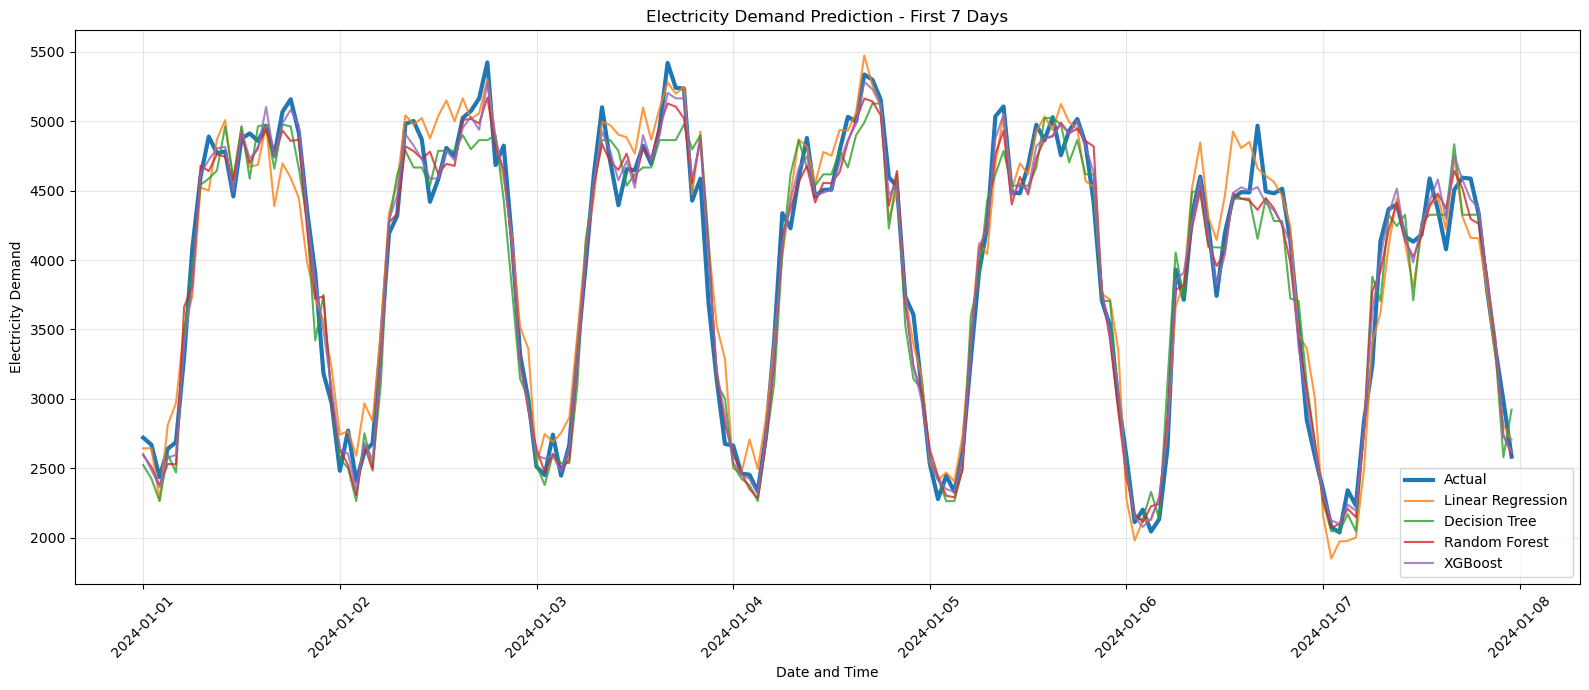

In [171]:
test_timestamps = (
    pd.to_datetime(X_test.index) +
    pd.to_timedelta(X_test['hour'].to_numpy(), unit='h')
)

plt.figure(figsize=(16, 7))

plt.plot(
    test_timestamps[:168],
    Y_test.iloc[:168],
    label='Actual',
    linewidth=3
)

for name, predictions in models_predictions.items():
    plt.plot(
        test_timestamps[:168],
        predictions[:168],
        label=name,
        alpha=0.8
    )

plt.title('Electricity Demand Prediction - First 7 Days')
plt.xlabel('Date and Time')
plt.ylabel('Electricity Demand')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()